In [1]:
import matplotlib.pyplot as plt
import geomstats.backend as gs
import geomstats.visualization as visualization
from geomstats.geometry.hypersphere import Hypersphere

/var/folders/xp/09_m9yj956x3kbv7qgpqgd6r0000gn/T/ipykernel_86767/2569498080.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


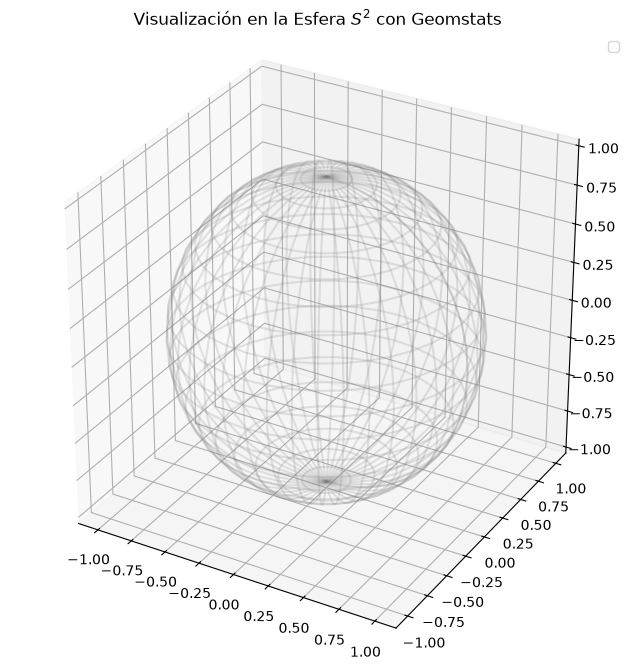

In [2]:
# 1. Definir la hiperesfera (dimensión 2, embebida en R^3)
sphere = Hypersphere(dim=2)

# 2. Generar puntos aleatorios sobre la esfera
points = sphere.random_uniform(n_samples=25)

# 3. Calcular la trayectoria más corta (geodésica) entre dos puntos
#initial_point = points[0]
#end_point = points[1]
#geodesic_func = sphere.metric.geodesic(initial_point=initial_point, end_point=end_point)
#geodesic_points = geodesic_func(gs.linspace(0.0, 1.0, 40))

# 4. Crear la figura 3D y renderizar
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

# Dibujar la superficie translúcida de la esfera
visualization.Sphere().draw(ax=ax, color="lightgray", alpha=0.2)

# Graficar los puntos y la geodésica
#visualization.plot(points, ax=ax, space="S2", color="royalblue", s=30, label="Puntos aleatorios")
#visualization.plot(initial_point, ax=ax, space="S2", color="green", s=100, label="Punto Inicial")
#visualization.plot(end_point, ax=ax, space="S2", color="crimson", s=100, label="Punto Final")
#visualization.plot(geodesic_points, ax=ax, space="S2", color="black", label="Geodésica")

ax.set_title("Visualización en la Esfera $S^2$ con Geomstats")
ax.legend()
plt.show()

INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral


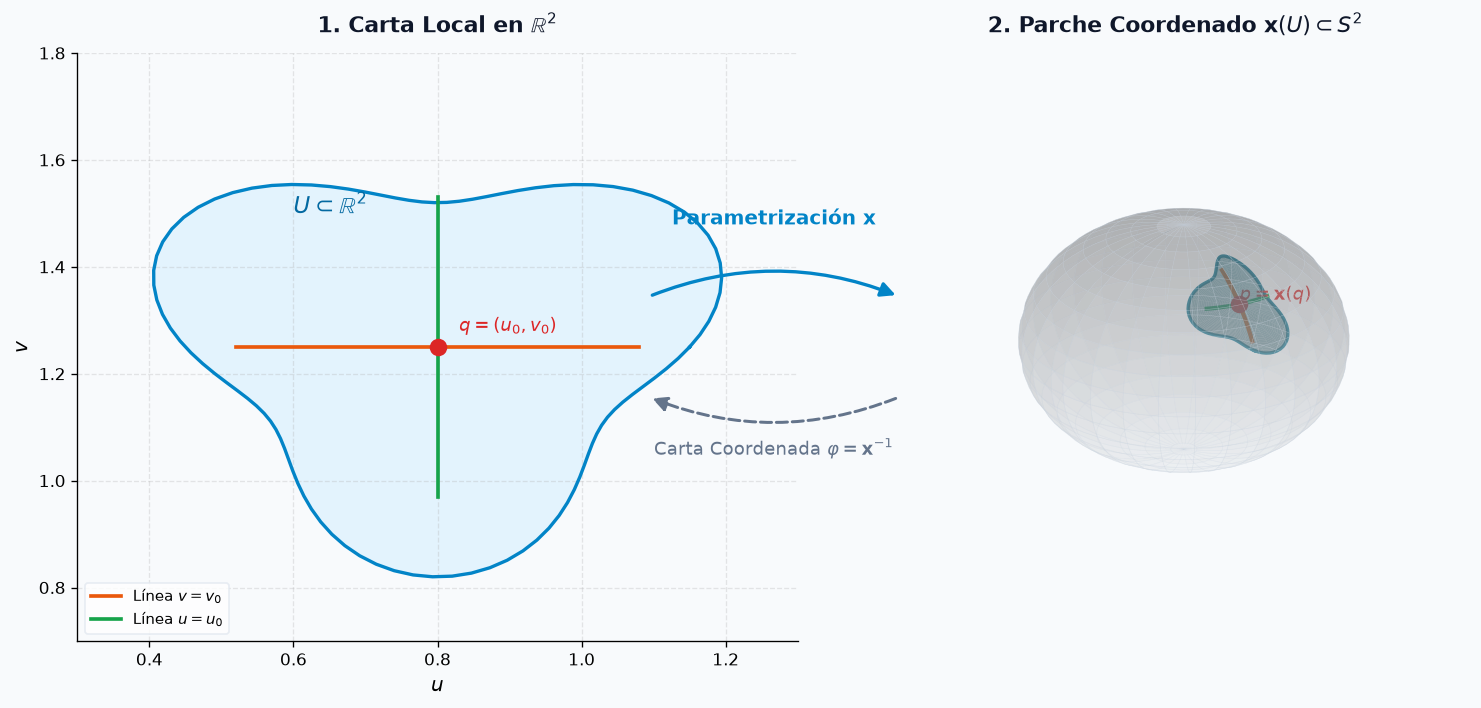

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Configuración de estilo y figura
fig = plt.figure(figsize=(13, 6), facecolor='#F8FAFC', dpi=120)

# ==========================================
# 1. IZQUIERDA: Carta en R^2 (Dominio Abierto U)
# ==========================================
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_facecolor('#F8FAFC')

# Geometría del dominio U (forma orgánica abierta)
t = np.linspace(0, 2 * np.pi, 100)
u_center, v_center = 0.8, 1.25
r_t = 0.35 + 0.08 * np.sin(3 * t)
u_bound = u_center + r_t * np.cos(t)
v_bound = v_center + r_t * np.sin(t)

# Dibujar dominio U
ax1.fill(u_bound, v_bound, color='#E0F2FE', alpha=0.85)
ax1.plot(u_bound, v_bound, color='#0284C7', linewidth=2)

# Líneas coordenadas en R^2 que se cruzan en q = (u0, v0)
u_range = np.linspace(u_center - 0.28, u_center + 0.28, 60)
v_range = np.linspace(v_center - 0.28, v_center + 0.28, 60)

ax1.plot(u_range, np.full_like(u_range, v_center), color='#EA580C', linewidth=2.2, label=r'Línea $v = v_0$')
ax1.plot(np.full_like(v_range, u_center), v_range, color='#16A34A', linewidth=2.2, label=r'Línea $u = u_0$')
ax1.scatter([u_center], [v_center], color='#DC2626', s=90, zorder=5)

# Etiquetas matematicas R^2
ax1.annotate(r'$q = (u_0, v_0)$', (u_center + 0.03, v_center + 0.03), fontsize=11, fontweight='bold', color='#DC2626')
ax1.text(u_center - 0.2, v_center + 0.25, r'$U \subset \mathbb{R}^2$', fontsize=14, fontweight='bold', color='#0369A1')

ax1.set_xlim(0.3, 1.3)
ax1.set_ylim(0.7, 1.8)
ax1.set_xlabel('$u$', fontsize=12)
ax1.set_ylabel('$v$', fontsize=12)
ax1.set_title(r'1. Carta Local en $\mathbb{R}^2$', fontsize=13, pad=12, color='#0F172A', fontweight='bold')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=9)

# ==========================================
# 2. DERECHA: Variedad S^2 con el parche x(U)
# ==========================================
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.set_facecolor('#F8FAFC')

# Malla base de la esfera S^2
theta = np.linspace(0, 2 * np.pi, 60)
phi = np.linspace(0, np.pi, 40)
THETA, PHI = np.meshgrid(theta, phi)
X_sp = np.sin(PHI) * np.cos(THETA)
Y_sp = np.sin(PHI) * np.sin(THETA)
Z_sp = np.cos(PHI)

ax2.plot_surface(X_sp, Y_sp, Z_sp, color='#F1F5F9', alpha=0.3, edgecolor='#CBD5E1', linewidth=0.3, rstride=2, cstride=2)

# Mapear el interior de U hacia S^2 mediante la parametrización x(u,v)
grid_r = np.linspace(0, 1, 30)
grid_t = np.linspace(0, 2 * np.pi, 40)
R_g, T_g = np.meshgrid(grid_r, grid_t)
U_mesh = u_center + R_g * (0.35 + 0.08 * np.sin(3 * T_g)) * np.cos(T_g)
V_mesh = v_center + R_g * (0.35 + 0.08 * np.sin(3 * T_g)) * np.sin(T_g)

X_m = np.sin(U_mesh) * np.cos(V_mesh)
Y_m = np.sin(U_mesh) * np.sin(V_mesh)
Z_m = np.cos(U_mesh)

# Superficie del parche x(U) y borde
X_b = np.sin(u_bound) * np.cos(v_bound)
Y_b = np.sin(u_bound) * np.sin(v_bound)
Z_b = np.cos(u_bound)

ax2.plot_surface(X_m, Y_m, Z_m, color='#0891B2', alpha=0.55, edgecolor='none')
ax2.plot(X_b, Y_b, Z_b, color='#0E7490', linewidth=2)

# Mapear curvas coordenadas sobre la variedad S^2
u_c_X = np.sin(u_range) * np.cos(v_center)
u_c_Y = np.sin(u_range) * np.sin(v_center)
u_c_Z = np.cos(u_range)

v_c_X = np.sin(u_center) * np.cos(v_range)
v_c_Y = np.sin(u_center) * np.sin(v_range)
v_c_Z = np.full_like(v_range, np.cos(u_center))

ax2.plot(u_c_X, u_c_Y, u_c_Z, color='#EA580C', linewidth=2.5, label=r'Curva $\mathbf{x}(u, v_0)$')
ax2.plot(v_c_X, v_c_Y, v_c_Z, color='#16A34A', linewidth=2.5, label=r'Curva $\mathbf{x}(u_0, v)$')

# Punto p = x(q) en la esfera
p_x = np.sin(u_center) * np.cos(v_center)
p_y = np.sin(u_center) * np.sin(v_center)
p_z = np.cos(u_center)
ax2.scatter([p_x], [p_y], [p_z], color='#DC2626', s=90, zorder=10)
ax2.text(p_x + 0.05, p_y + 0.05, p_z + 0.08, r'$p = \mathbf{x}(q)$', fontsize=11, fontweight='bold', color='#DC2626')

ax2.set_title(r'2. Parche Coordenado $\mathbf{x}(U) \subset S^2$', fontsize=13, pad=12, color='#0F172A', fontweight='bold')
ax2.view_init(elev=25, azim=45)
ax2.axis('off')

# ==========================================
# 3. CENTRO: Flechas de Mapeo Diferenciable
# ==========================================
arrow_forward = FancyArrowPatch((0.42, 0.58), (0.58, 0.58),
                                transform=fig.transFigure,
                                connectionstyle="arc3,rad=-0.2",
                                arrowstyle="-|>",
                                mutation_scale=18,
                                linewidth=2,
                                color='#0284C7')

arrow_backward = FancyArrowPatch((0.58, 0.44), (0.42, 0.44),
                                 transform=fig.transFigure,
                                 connectionstyle="arc3,rad=-0.2",
                                 arrowstyle="-|>",
                                 mutation_scale=18,
                                 linewidth=1.8,
                                 linestyle='--',
                                 color='#64748B')

fig.patches.extend([arrow_forward, arrow_backward])

fig.text(0.5, 0.68, r'Parametrización $\mathbf{x}$', fontsize=12, fontweight='bold', color='#0284C7', ha='center')
fig.text(0.5, 0.36, r'Carta Coordenada $\varphi = \mathbf{x}^{-1}$', fontsize=11, color='#64748B', ha='center')

plt.tight_layout()
plt.show()

INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral


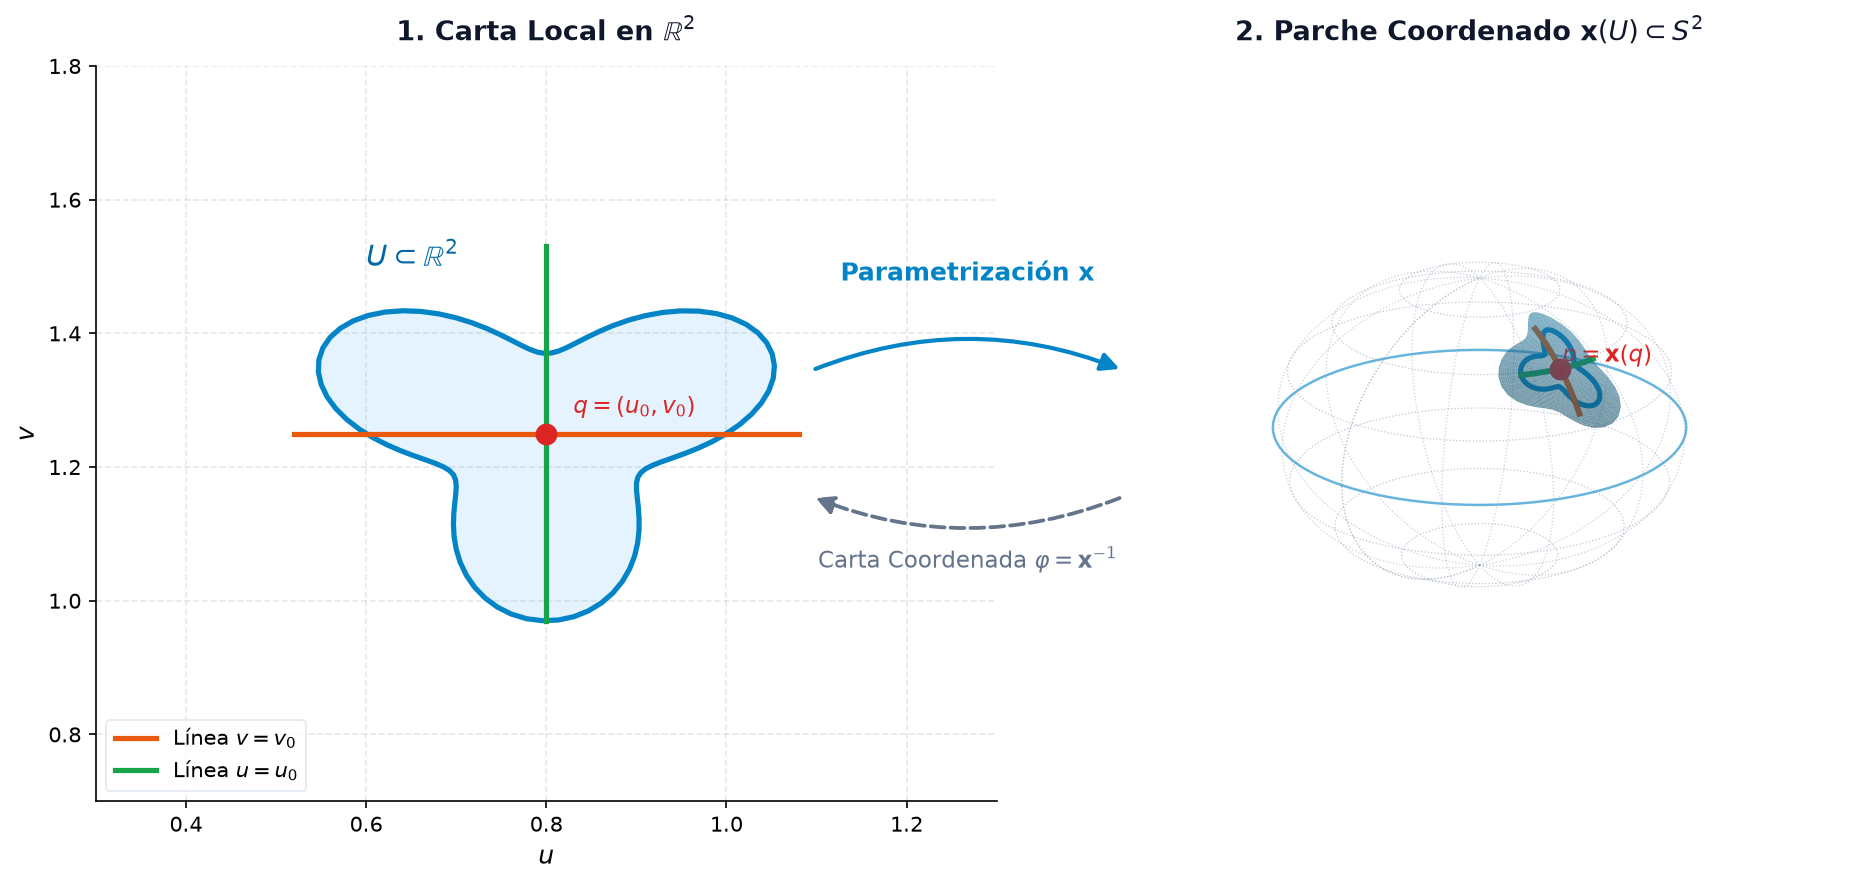

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Configuración de figura con fondo blanco pulcro
fig = plt.figure(figsize=(13, 6), facecolor='#FFFFFF', dpi=150)

# ==========================================
# 1. IZQUIERDA: Carta en R^2 (Dominio U)
# ==========================================
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_facecolor('#FFFFFF')

# Dominio U (forma suave en R^2)
t = np.linspace(0, 2 * np.pi, 100)
u_center, v_center = 0.8, 1.25
r_t = 0.2 + 0.08 * np.sin(3 * t)
u_bound = u_center + r_t * np.cos(t)
v_bound = v_center + r_t * np.sin(t)

ax1.fill(u_bound, v_bound, color='#E0F2FE', alpha=0.85)
ax1.plot(u_bound, v_bound, color='#0284C7', linewidth=2.5)

# Líneas coordenadas que se cruzan en q = (u0, v0)
u_range = np.linspace(u_center - 0.28, u_center + 0.28, 60)
v_range = np.linspace(v_center - 0.28, v_center + 0.28, 60)

ax1.plot(u_range, np.full_like(u_range, v_center), color='#EA580C', linewidth=2.5, label=r'Línea $v = v_0$')
ax1.plot(np.full_like(v_range, u_center), v_range, color='#16A34A', linewidth=2.5, label=r'Línea $u = u_0$')
ax1.scatter([u_center], [v_center], color='#DC2626', s=90, zorder=5)

ax1.annotate(r'$q = (u_0, v_0)$', (u_center + 0.03, v_center + 0.03), fontsize=11, fontweight='bold', color='#DC2626')
ax1.text(u_center - 0.2, v_center + 0.25, r'$U \subset \mathbb{R}^2$', fontsize=14, fontweight='bold', color='#0369A1')

ax1.set_xlim(0.3, 1.3)
ax1.set_ylim(0.7, 1.8)
ax1.set_xlabel('$u$', fontsize=12)
ax1.set_ylabel('$v$', fontsize=12)
ax1.set_title(r'1. Carta Local en $\mathbb{R}^2$', fontsize=13, pad=12, color='#0F172A', fontweight='bold')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=10)

# ==========================================
# 2. DERECHA: Esfera S^2 Transparente / Cristalina
# ==========================================
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.set_facecolor("#FFFFFF")

# Estructura de alambre ligero para una esfera 100% transparente
latitudes = np.linspace(-np.pi / 2, np.pi / 2, 9)
longitudes = np.linspace(0, 2 * np.pi, 13)

# Dibujar paralelos y ecuador
for lat in latitudes:
    t_line = np.linspace(0, 2 * np.pi, 100)
    x_l = np.cos(lat) * np.cos(t_line)
    y_l = np.cos(lat) * np.sin(t_line)
    z_l = np.full_like(t_line, np.sin(lat))
    is_equator = np.isclose(lat, 0)
    ax2.plot(x_l, y_l, z_l, color='#0284C7' if is_equator else '#94A3B8',
             linewidth=1.2 if is_equator else 0.6,
             linestyle='-' if is_equator else ':', alpha=0.6)

# Dibujar meridianos
for lon in longitudes:
    p_line = np.linspace(-np.pi / 2, np.pi / 2, 100)
    x_l = np.cos(p_line) * np.cos(lon)
    y_l = np.cos(p_line) * np.sin(lon)
    z_l = np.sin(p_line)
    ax2.plot(x_l, y_l, z_l, color='#94A3B8', linewidth=0.6, linestyle=':', alpha=0.5)

# Parche Coordenado x(U) sobre la esfera
grid_r = np.linspace(0, 1, 35)
grid_t = np.linspace(0, 2 * np.pi, 45)
R_g, T_g = np.meshgrid(grid_r, grid_t)
U_mesh = u_center + R_g * (0.35 + 0.08 * np.sin(3 * T_g)) * np.cos(T_g)
V_mesh = v_center + R_g * (0.35 + 0.08 * np.sin(3 * T_g)) * np.sin(T_g)

X_m = np.sin(U_mesh) * np.cos(V_mesh)
Y_m = np.sin(U_mesh) * np.sin(V_mesh)
Z_m = np.cos(U_mesh)

X_b = np.sin(u_bound) * np.cos(v_bound)
Y_b = np.sin(u_bound) * np.sin(v_bound)
Z_b = np.cos(u_bound)

# Relleno del parche semitransparente con borde azul
ax2.plot_surface(X_m, Y_m, Z_m, color='#38BDF8', alpha=0.6, edgecolor='none')
ax2.plot(X_b, Y_b, Z_b, color='#0284C7', linewidth=2.5)

# Curvas coordenadas mapeadas sobre S^2
u_c_X = np.sin(u_range) * np.cos(v_center)
u_c_Y = np.sin(u_range) * np.sin(v_center)
u_c_Z = np.cos(u_range)

v_c_X = np.sin(u_center) * np.cos(v_range)
v_c_Y = np.sin(u_center) * np.sin(v_range)
v_c_Z = np.full_like(v_range, np.cos(u_center))

ax2.plot(u_c_X, u_c_Y, u_c_Z, color='#EA580C', linewidth=2.8, label=r'Curva $\mathbf{x}(u, v_0)$')
ax2.plot(v_c_X, v_c_Y, v_c_Z, color='#16A34A', linewidth=2.8, label=r'Curva $\mathbf{x}(u_0, v)$')

# Punto p = x(q)
p_x = np.sin(u_center) * np.cos(v_center)
p_y = np.sin(u_center) * np.sin(v_center)
p_z = np.cos(u_center)
ax2.scatter([p_x], [p_y], [p_z], color='#DC2626', s=90, zorder=10)
ax2.text(p_x + 0.05, p_y + 0.05, p_z + 0.08, r'$p = \mathbf{x}(q)$', fontsize=11, fontweight='bold', color='#DC2626')

ax2.set_title(r'2. Parche Coordenado $\mathbf{x}(U) \subset S^2$', fontsize=13, pad=12, color='#0F172A', fontweight='bold')
ax2.view_init(elev=22, azim=40)
ax2.axis('off')

# ==========================================
# 3. CENTRO: Flechas de Mapeo Inter-paneles
# ==========================================
arrow_forward = FancyArrowPatch((0.42, 0.58), (0.58, 0.58),
                                transform=fig.transFigure,
                                connectionstyle="arc3,rad=-0.2",
                                arrowstyle="-|>",
                                mutation_scale=18,
                                linewidth=2,
                                color='#0284C7')

arrow_backward = FancyArrowPatch((0.58, 0.44), (0.42, 0.44),
                                 transform=fig.transFigure,
                                 connectionstyle="arc3,rad=-0.2",
                                 arrowstyle="-|>",
                                 mutation_scale=18,
                                 linewidth=1.8,
                                 linestyle='--',
                                 color='#64748B')

fig.patches.extend([arrow_forward, arrow_backward])

fig.text(0.5, 0.68, r'Parametrización $\mathbf{x}$', fontsize=12, fontweight='bold', color='#0284C7', ha='center')
fig.text(0.5, 0.36, r'Carta Coordenada $\varphi = \mathbf{x}^{-1}$', fontsize=11, color='#64748B', ha='center')

plt.tight_layout()
plt.show()